# Experiment: XAUUSD ML Bull / ML Bear v0.2 (walk-forward experiments)

**คำถาม:** แก้จุดอ่อนของ v0.1 (label ทับกัน, validation ก้อนเล็ก, เลือก τ/m ตาม regime) แล้วโมเดลจะ **ชนะ always-long** ได้ไหม — ไม่ใช่แค่ PF > 1

**เกณฑ์ความสำเร็จ (ตั้งไว้ก่อนรัน):** บนช่วง out-of-sample แบบ nested (มิ.ย. 2025 → ม.ค. 2026) expectancy ของโมเดล − expectancy ของ always-long มีขอบล่างของ CI 90% (bootstrap) **> 0**

| | v0.1 | v0.2 |
|---|---|---|
| ประเมินผล | train/val/test ก้อนเดียว | **expanding walk-forward รายเดือน** (เม.ย. 2025 → ม.ค. 2026), purge/embargo = time stop |
| calibration + τ/m | fit บน validation ก้อนเดียว | **nested**: เดือน k ใช้ calibrator และ τ/m ที่เลือกจาก out-of-fold ของเดือนก่อน k เท่านั้น |
| label ทับกัน | ไม่จัดการ | **uniqueness weights** (López de Prado) |
| การทดลอง | 1 แบบ | **6 แบบ กำหนดไว้ก่อน** (E0–E5) เลือกด้วย AUC เฉลี่ยข้าม fold (ไม่ขึ้นกับ threshold) |
| feature | 53/44 ตัว | + ระดับราคา (high/low วันก่อน/สัปดาห์ก่อน, กรอบวันนี้) + session |
| label set | base + ct25 | **ct25** (ตรงกับ policy `counter_trend_risk_reward` ของระบบตอนนี้) |

⚠️ **ไม่มี holdout สะอาด:** ข้อมูลมีถึง 2026-01-30 และช่วง 2025-10 → 2026-01 เคยถูกเปิดดูเป็น test ของ v0.1 แล้ว จึงรายงานแยก "ช่วงที่เคยเห็น" vs "ช่วงที่ไม่เคยเห็น" — คำตัดสินสุดท้ายต้องมาจาก backtest Aug–Sep 2026 ผ่าน API ของ harness (ข้อมูลช่วงนั้นยังหาไม่ได้: Dukascopy เชื่อมต่อจากเครื่องนี้ไม่ได้, Yahoo มีแค่ futures `GC=F` และ 15m ย้อนหลัง 60 วัน)

In [1]:
# Setup: imports and reproducibility
from __future__ import annotations

import dataclasses
import hashlib
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybroker as pyb
import shap
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

NB_DIR = Path.cwd()
assert (NB_DIR / "xau_ml").is_dir(), "เปิด notebook จาก Product/notebook/"
sys.path.insert(0, str(NB_DIR))
from xau_ml import config as C  # noqa: E402
from xau_ml import cv as CV  # noqa: E402
from xau_ml import data as D  # noqa: E402
from xau_ml import features as F  # noqa: E402
from xau_ml import labels as L  # noqa: E402
from xau_ml import pb as P  # noqa: E402
from xau_ml import predictor as PR  # noqa: E402
from xau_ml import sim as S  # noqa: E402
from xau_ml import v2 as V  # noqa: E402
from xau_ml.model import Calibrator  # noqa: E402

SEED = 42
np.random.seed(SEED)
pyb.disable_progress_bar()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)
SIDES = ("bull", "bear")
LS = C.LABEL_SETS["ct25"]
print(f"pybroker {pyb.__version__} | lightgbm {V.lgb_version()} | version {C.VERSION_V2} | label set {LS.name}")

pybroker 2.0.1 | lightgbm 4.7.0 | version xau-bullbear-0.2.0 | label set ct25


## 1. ข้อมูล + feature + label

ข้อมูลชุดเดิม (ผลตรวจอยู่ใน notebook v0.1 §1): ใช้ 2025-01-02 → 2026-01-30, แท่งก่อนหน้าเป็น warm-up เท่านั้น, ช่วงข้อมูลหาย 2 ช่วงถูกกันด้วย `no_entry`

**feature ใหม่ (`features.add_extras`)** — รู้ได้ ณ เวลาปิดแท่งตัดสินใจทั้งหมด: กรอบ high/low ของวันนี้ถึงตอนนี้ (`day_range_atr`, `day_pos`), ระยะจาก high/low ของ **วันก่อน** และ **สัปดาห์ก่อน** หน่วย ATR (สัปดาห์ใช้ได้หลังจบปฏิทินสัปดาห์เท่านั้น), `session` (เอเชีย/ลอนดอน/นิวยอร์ก จากชั่วโมง server = NY + 7 ชม.)

In [2]:
RAW = {tf: D.load(tf, C.WARMUP_START[tf]) for tf in ("15m", "1h", "1d")}
FR, COLS = {}, {}
for hz in C.HORIZONS.values():
    base = F.build(RAW[hz.tf], hz.tf, {tf: RAW[tf] for tf in hz.htf})
    FR[hz.name] = L.add_labels(F.add_extras(base, RAW["1d"]), hz, LS)
    COLS[hz.name] = F.feature_columns(FR[hz.name])
    assert set(V.EXTRA_COLS) <= set(COLS[hz.name])
    st = FR[hz.name].query("date >= @C.TRAIN[0]")
    print(f"{hz.name}: {len(COLS[hz.name])} features (incl. {len(V.EXTRA_COLS)} new) | usable rows {int(CV.usable(st).sum()):,} "
          f"| long wins {st['y_bull'].mean():.3f} short wins {st['y_bear'].mean():.3f} | both win: {int(((st['y_bull'] == 1) & (st['y_bear'] == 1)).sum())}")

intraday: 60 features (incl. 7 new) | usable rows 22,328 | long wins 0.323 short wins 0.171 | both win: 0


swing: 51 features (incl. 7 new) | usable rows 5,263 | long wins 0.453 short wins 0.183 | both win: 0


In [3]:
# Look-ahead: rebuild every feature (incl. the new ones) from data cut at the decision time
rng = np.random.default_rng(SEED)
for hz in C.HORIZONS.values():
    fr, cols = FR[hz.name], COLS[hz.name]
    for tc in F.TIME_COLS:
        if tc in fr:
            assert (fr[tc].isna() | (fr[tc] <= fr["t_close"])).all(), tc
    worst = 0.0
    for t in rng.choice(np.flatnonzero(fr["date"] >= C.TRAIN[0]), 40, replace=False):
        row = fr.iloc[t]
        cut = {tf: RAW[tf][RAW[tf]["t_close"] <= row["t_close"]] for tf in ("15m", "1h", "1d")}
        main = RAW[hz.tf][RAW[hz.tf]["date"] <= row["date"]]
        again = F.add_extras(F.build(main, hz.tf, {tf: cut[tf] for tf in hz.htf}), cut["1d"]).iloc[-1]
        a, b = row[cols].to_numpy(float), again[cols].to_numpy(float)
        assert np.array_equal(np.isnan(a), np.isnan(b)), (hz.name, row["date"])
        worst = max(worst, float(np.nanmax(np.abs(a - b))))
    assert worst < 1e-9, (hz.name, worst)
    assert not [c for c in cols if c.startswith(F.LABEL_PREFIXES)]
    print(f"{hz.name}: truncation test on 40 rows incl. new features, max |diff| = {worst:.1e} ✓")

intraday: truncation test on 40 rows incl. new features, max |diff| = 0.0e+00 ✓


swing: truncation test on 40 rows incl. new features, max |diff| = 0.0e+00 ✓


## 2. Protocol: expanding walk-forward รายเดือน

- fold = เดือนปฏิทิน เม.ย. 2025 → ม.ค. 2026 · train = ทุกแถวที่ใช้ได้ตั้งแต่ 2025-01-02 จนถึงก่อนเดือนนั้น (**purge** แถวที่หน้าต่าง label ล้ำเข้าเดือน) · **embargo** `time_stop` แถวแรกของเดือน
- **nested:** เดือน k เทรดด้วย Platt calibrator + τ/m ที่เลือกจาก out-of-fold ของเดือน < k เท่านั้น (เกณฑ์ τ/m เหมือน v0.1: Σr/√n, ≥ 40/15 เทรด, PF > 1) — เม.ย.–พ.ค. เป็น burn-in (ใช้เลือกอย่างเดียว ไม่นับผลเทรด)
- เดือน ก.ย.–ต.ค. 2025 สั้นเพราะข้อมูลหาย

In [4]:
FOLDS = {}
rows = []
for hz in C.HORIZONS.values():
    folds = CV.monthly_folds(FR[hz.name], hz, C.WF2_FIRST_FOLD, C.WF2_LAST_FOLD, C.TRAIN[0])
    CV.assert_folds(FR[hz.name], folds, hz)
    FOLDS[hz.name] = folds
    for f in folds:
        rows.append({"horizon": hz.name, "fold": f.name, "train_rows": len(f.train), "test_rows": len(f.test),
                     "train_to": FR[hz.name]["date"].iloc[f.train].max(), "test_from": FR[hz.name]["date"].iloc[f.test].min()})
print("purge/embargo: no training label reaches its test month ✓")
display(pd.DataFrame(rows).pivot_table(index="fold", columns="horizon", values=["train_rows", "test_rows"]))

purge/embargo: no training label reaches its test month ✓


test_rows          train_rows          
horizon  intraday    swing   intraday     swing
fold                                           
2025-04 1916.0000 435.0000  5745.0000 1394.0000
2025-05 1993.0000 456.0000  7677.0000 1877.0000
2025-06 1906.0000 433.0000  9686.0000 2381.0000
2025-07 2024.0000 464.0000 11608.0000 2862.0000
2025-08 1916.0000 435.0000 13648.0000 3374.0000
2025-09  877.0000 131.0000 15580.0000 3857.0000
2025-10  969.0000  93.0000 16490.0000 4085.0000
2025-11 1805.0000 408.0000 17442.0000 4129.0000
2025-12 1995.0000 455.0000 19263.0000 4585.0000
2026-01 1021.0000  78.0000 21274.0000 5088.0000

## 3. การทดลอง E0–E5 (กำหนดไว้ก่อนรัน)

**กฎเลือก (ประกาศก่อนเห็นผล):** ต่อ horizon เลือกการทดลองที่ **AUC เฉลี่ยข้าม fold (เฉลี่ย bull และ bear) สูงสุด** — ไม่ใช้ผลเทรดในการเลือก เพื่อไม่ให้ไปจูนตาม P&L ของช่วงเดียวกัน · ผลเทรดของทุกการทดลองรายงานไว้ให้ดูครบ

In [5]:
OOF, FOLD_ML, rows = {}, {}, []
for hz in C.HORIZONS.values():
    for exp in V.EXPERIMENTS:
        cols = V.columns(exp, COLS[hz.name])
        oof, per_fold = V.run_oof(exp, FR[hz.name], FOLDS[hz.name], cols, hz)
        OOF[(hz.name, exp.id)], FOLD_ML[(hz.name, exp.id)] = oof, per_fold
        rows.append({"horizon": hz.name, "exp": exp.id, "name": exp.name, "features": len(cols),
                     "auc_bull": per_fold["auc_bull"].mean(), "auc_bear": per_fold["auc_bear"].mean(),
                     "auc_mean": per_fold[["auc_bull", "auc_bear"]].mean(axis=1).mean(),
                     "auc_bull_min_fold": per_fold["auc_bull"].min(), "auc_bear_min_fold": per_fold["auc_bear"].min(),
                     "logloss_gain_bull": (per_fold["logloss_clim_bull"] - per_fold["logloss_bull"]).mean(),
                     "logloss_gain_bear": (per_fold["logloss_clim_bear"] - per_fold["logloss_bear"]).mean()})
ML_TABLE = pd.DataFrame(rows)
display(ML_TABLE)

,horizon,exp,name,features,auc_bull,auc_bear,auc_mean,auc_bull_min_fold,auc_bear_min_fold,logloss_gain_bull,logloss_gain_bear
0,intraday,E0,"v0.1 setup (LightGBM pair, no weights)",53,0.5619,0.6113,0.5866,0.4888,0.5519,-0.0005,0.0029
1,intraday,E1,LightGBM pair + uniqueness weights,53,0.5594,0.6002,0.5798,0.4922,0.5052,0.0012,0.0015
2,intraday,E2,Logistic regression pair + weights,53,0.5180,0.5740,0.5460,0.4719,0.4938,-0.0673,-0.0399
3,intraday,E3,"LightGBM pair + weights, reduced features",20,0.5725,0.6170,0.5948,0.4885,0.5791,0.0049,0.0040
4,intraday,E4,LightGBM 3-class (long/short/none) + weights,53,0.5594,0.6126,0.5860,0.4817,0.5366,-0.0022,0.0078
5,intraday,E5,LightGBM pair + weights + level/session features,60,0.5503,0.6043,0.5773,0.4750,0.5575,-0.0001,0.0059
6,swing,E0,"v0.1 setup (LightGBM pair, no weights)",44,0.5505,0.5804,0.5654,0.3691,0.3480,-0.0074,-0.0891
7,swing,E1,LightGBM pair + uniqueness weights,44,0.5466,0.5371,0.5419,0.3415,0.0659,-0.0027,-0.0669
8,swing,E2,Logistic regression pair + weights,44,0.5294,0.5177,0.5236,0.4011,0.1959,-0.1184,-0.1902
9,swing,E3,"LightGBM pair + weights, reduced features",20,0.5715,0.5977,0.5846,0.3499,0.2264,-0.0142,-0.0616


**อ่านผล:** E3 (feature 20 ตัว + weights) ได้ AUC เฉลี่ยสูงสุดทั้งสอง horizon; logistic (E2) แย่สุด; feature ระดับราคา (E5) ไม่ช่วย · คอลัมน์ `*_min_fold` บอกว่าบางเดือน bull model แย่กว่าสุ่ม แต่ bear model ของ intraday ไม่ต่ำกว่า 0.58 เลยใน E3

In [6]:
# Nested out-of-sample trading for every experiment + baselines on exactly the same decision rows
TRADE, TRADES, NEST = [], {}, {}
for hz in C.HORIZONS.values():
    fr, names = FR[hz.name], [f.name for f in FOLDS[hz.name]]
    for exp in V.EXPERIMENTS:
        trades, log, cal, sig, scored = V.nested_trading(fr, OOF[(hz.name, exp.id)], names, C.WF2_BURN_IN, C.MIN_VAL_TRADES[hz.tf])
        TRADES[(hz.name, exp.id)], NEST[(hz.name, exp.id)] = trades, (log, cal, sig, scored)
        TRADE.append({"horizon": hz.name, "strategy": exp.id, **S.metrics(trades)})
    oof0 = OOF[(hz.name, "E0")]
    scored_pos = oof0["pos"].to_numpy()[oof0["fold"].isin(names[C.WF2_BURN_IN:]).to_numpy()]
    for kind in ("always_long", "always_short", "sma20_50_cross"):
        t = V.baseline_trades(fr, scored_pos, kind)
        TRADES[(hz.name, kind)] = t
        TRADE.append({"horizon": hz.name, "strategy": kind, **S.metrics(t)})
TRADE = pd.DataFrame(TRADE)
# bootstrap: expectancy CI and the difference vs always-long (the success criterion)
for i, r in TRADE.iterrows():
    t = TRADES[(r["horizon"], r["strategy"])]
    lo, hi = CV.bootstrap_mean_ci(t["r"].to_numpy()) if len(t) else (np.nan, np.nan)
    dlo, dhi = CV.bootstrap_diff_ci(t["r"].to_numpy(), TRADES[(r["horizon"], "always_long")]["r"].to_numpy()) if len(t) else (np.nan, np.nan)
    TRADE.loc[i, ["exp_ci90_lo", "exp_ci90_hi", "vs_long_ci90_lo", "vs_long_ci90_hi"]] = [lo, hi, dlo, dhi]
TRADE["beats_always_long"] = TRADE["vs_long_ci90_lo"] > 0
display(TRADE[["horizon", "strategy", "trades", "win_rate", "profit_factor", "expectancy_r", "exp_ci90_lo", "exp_ci90_hi",
               "vs_long_ci90_lo", "vs_long_ci90_hi", "beats_always_long", "max_dd_pct", "long_share"]])

,horizon,strategy,trades,win_rate,profit_factor,expectancy_r,exp_ci90_lo,exp_ci90_hi,vs_long_ci90_lo,vs_long_ci90_hi,beats_always_long,max_dd_pct,long_share
0,intraday,E0,192,0.4531,1.0949,0.0499,-0.0956,0.1918,-0.0947,0.2079,False,16.8898,0.5677
1,intraday,E1,321,0.4486,1.0081,0.0044,-0.1006,0.1093,-0.1000,0.1270,False,25.0822,1.0000
2,intraday,E2,12,0.5833,1.3555,0.1027,-0.3026,0.5086,-0.2926,0.5197,False,1.4343,1.0000
3,intraday,E3,79,0.4810,1.0772,0.0383,-0.1573,0.2494,-0.1539,0.2637,False,13.6085,0.8481
4,intraday,E4,199,0.4673,1.0499,0.0238,-0.0985,0.1475,-0.1003,0.1668,False,15.9951,0.9698
5,intraday,E5,141,0.4752,1.1498,0.0722,-0.0791,0.2259,-0.0803,0.2422,False,17.5731,1.0000
6,intraday,always_long,1608,0.4335,0.9841,-0.0088,-0.0580,0.0384,-0.0680,0.0679,False,53.3379,1.0000
7,intraday,always_short,1374,0.3603,0.8512,-0.0918,-0.1483,-0.0346,-0.1577,-0.0089,False,78.9322,0.0000
8,intraday,sma20_50_cross,262,0.4351,1.1539,0.0836,-0.0485,0.2189,-0.0471,0.2354,False,14.5565,0.4885
9,swing,E0,111,0.4775,1.3388,0.1721,-0.0110,0.3629,-0.2628,0.2298,False,8.3051,1.0000


**อ่านผล:** ไม่มีแถวไหนที่ `beats_always_long` = True · swing มี expectancy บวกอย่างมีนัยสำคัญ (CI ไม่คร่อม 0) ทั้ง E3, E4 และ always-long เอง — คือ regime ขาขึ้น ไม่ใช่ skill · always-short ติดลบทุกตัว

## 4. เลือกการทดลอง (ตามกฎที่ประกาศไว้) และดูรายละเอียด

In [7]:
CHOSEN = {}
for hz in C.HORIZONS.values():
    t = ML_TABLE[ML_TABLE["horizon"] == hz.name].sort_values("auc_mean", ascending=False)
    CHOSEN[hz.name] = next(e for e in V.EXPERIMENTS if e.id == t.iloc[0]["exp"])
    print(f"{hz.name}: chosen {CHOSEN[hz.name].id} — {CHOSEN[hz.name].name} (mean fold AUC {t.iloc[0]['auc_mean']:.4f}; "
          f"runner-up {t.iloc[1]['exp']} {t.iloc[1]['auc_mean']:.4f})")
for hzn, exp in CHOSEN.items():
    key = (hzn, exp.id)
    log, cal, sig, scored = NEST[key]
    per = FOLD_ML[key][["fold", "train_rows", "test_rows", "auc_bull", "auc_bear"]].merge(log, on="fold", how="left")
    t = TRADES[key]
    if len(t):
        by_month = t.groupby(pd.to_datetime(t["entry"]).dt.to_period("M").astype(str)).agg(trades=("r", "size"), total_r=("r", "sum"),
                                                                                         long=("side", lambda s: (s == "long").mean()))
        per = per.merge(by_month, left_on="fold", right_index=True, how="left")
    print(f"\n{hzn} / {exp.id}: per-fold AUC, nested tau/m and trades")
    display(per)

intraday: chosen E3 — LightGBM pair + weights, reduced features (mean fold AUC 0.5948; runner-up E0 0.5866)
swing: chosen E3 — LightGBM pair + weights, reduced features (mean fold AUC 0.5846; runner-up E0 0.5654)

intraday / E3: per-fold AUC, nested tau/m and trades


,fold,train_rows,test_rows,auc_bull,auc_bear,tau,m,trades_prior_at_choice,signals,long_signals,trades,total_r,long
0,2025-04,5745,1916,0.4885,0.6591,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-05,7677,1993,0.5224,0.6320,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-06,9686,1906,0.6160,0.5791,0.3500,0.0000,43.0000,83.0000,0.0000,12.0000,-3.3884,0.0000
3,2025-07,11608,2024,0.6104,0.6594,0.3000,0.2000,139.0000,0.0000,0.0000,NaN,NaN,NaN
4,2025-08,13648,1916,0.5579,0.5797,0.3000,0.2000,156.0000,104.0000,104.0000,19.0000,-9.2637,1.0000
5,2025-09,15580,877,0.6727,0.5882,0.3250,0.2000,112.0000,4.0000,4.0000,1.0000,0.0847,1.0000
6,2025-10,16490,969,0.6070,0.5924,0.3250,0.1500,452.0000,56.0000,56.0000,8.0000,1.0229,1.0000
7,2025-11,17442,1805,0.5607,0.5953,0.3250,0.1500,451.0000,211.0000,211.0000,34.0000,16.0688,1.0000
8,2025-12,19263,1995,0.5916,0.5960,0.3500,0.2000,224.0000,0.0000,0.0000,NaN,NaN,NaN
9,2026-01,21274,1021,0.4981,0.6889,0.3000,0.2000,399.0000,29.0000,29.0000,5.0000,-1.5021,1.0000



swing / E3: per-fold AUC, nested tau/m and trades


,fold,train_rows,test_rows,auc_bull,auc_bear,tau,m,trades_prior_at_choice,signals,long_signals,trades,total_r,long
0,2025-04,1394,435,0.5572,0.7381,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-05,1877,456,0.5654,0.5759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-06,2381,433,0.7193,0.6243,0.4000,0.1500,19.0000,28.0000,28.0000,4.0000,-1.0646,1.0000
3,2025-07,2862,464,0.5725,0.4087,0.3500,0.0000,98.0000,464.0000,464.0000,28.0000,1.4888,1.0000
4,2025-08,3374,435,0.5405,0.5791,0.3250,0.0000,126.0000,435.0000,435.0000,26.0000,4.6693,1.0000
5,2025-09,3857,131,0.6685,0.2264,0.3250,0.0000,152.0000,131.0000,131.0000,8.0000,6.4659,1.0000
6,2025-10,4085,93,0.3499,0.8218,0.3500,0.0000,160.0000,93.0000,93.0000,6.0000,-0.0890,1.0000
7,2025-11,4129,408,0.6532,0.8922,0.3500,0.0500,166.0000,408.0000,408.0000,26.0000,9.1407,1.0000
8,2025-12,4585,455,0.6551,0.6680,0.3750,0.1500,161.0000,455.0000,455.0000,33.0000,7.5789,1.0000
9,2026-01,5088,78,0.4333,0.4426,0.4000,0.2000,189.0000,72.0000,72.0000,3.0000,2.4185,1.0000


**อ่านผล:** τ/m ที่ nested เลือกให้แต่ละเดือนเปลี่ยนไปตามข้อมูลก่อนหน้า (ไม่มีการมองอนาคต) · swing ส่วนใหญ่ = สัญญาณ long ทุกแท่ง (`signals` = `test_rows`) · intraday เดือน ส.ค. เสีย −9.3R จาก long 104 สัญญาณ

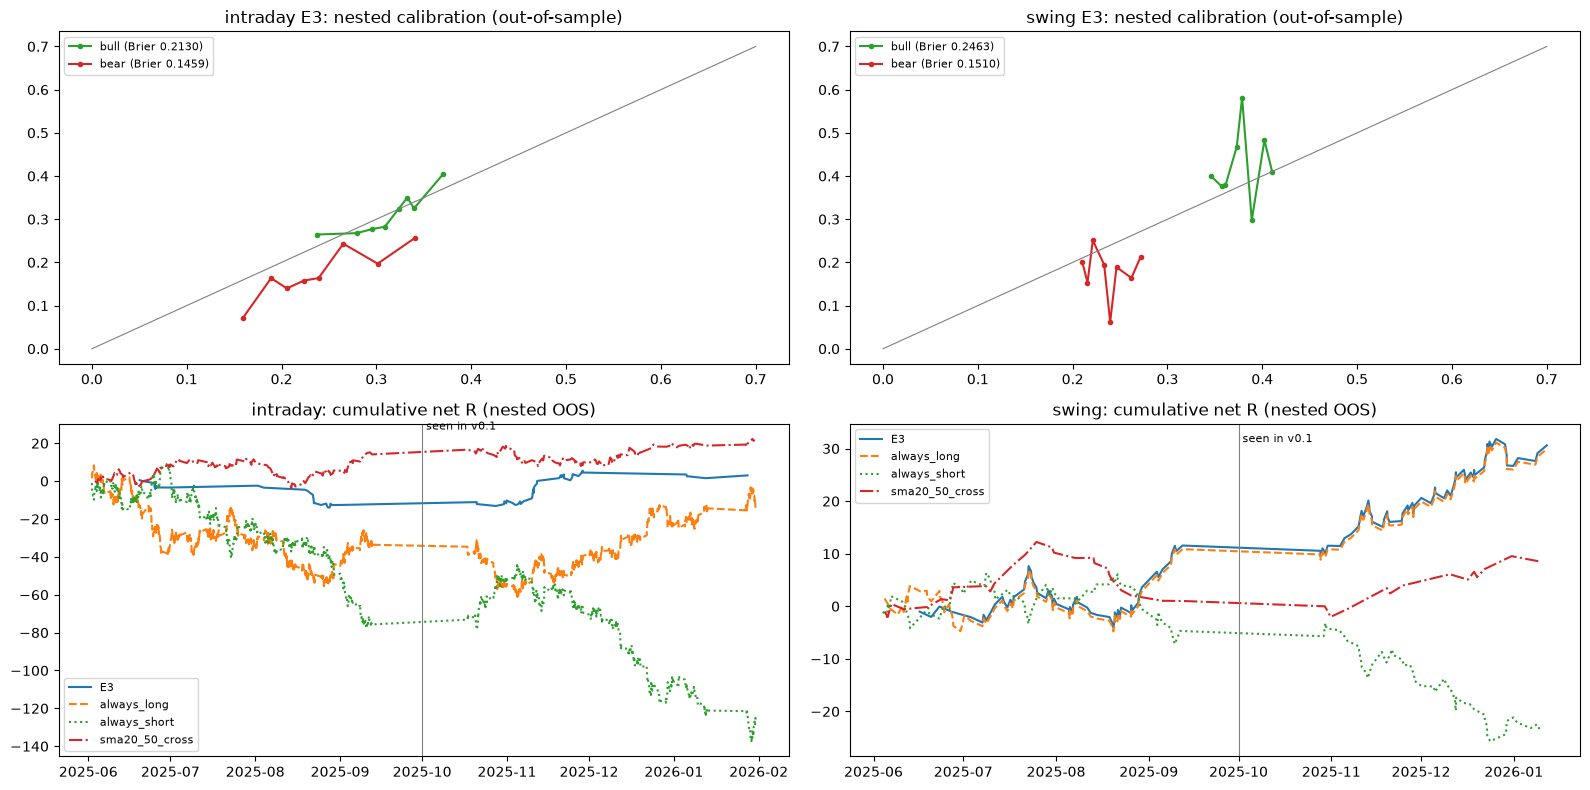

In [8]:
# Calibration (nested Platt, out-of-sample) + cumulative R vs baselines
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for col, (hzn, exp) in enumerate(CHOSEN.items()):
    fr, (log, cal, sig, scored) = FR[hzn], NEST[(hzn, exp.id)]
    oof = OOF[(hzn, exp.id)]
    ax = axes[0, col]
    for s, color in zip(SIDES, ("tab:green", "tab:red")):
        m = scored & cal[f"p_{s}"].notna().to_numpy()
        y = fr[f"y_{s}"].to_numpy()[oof["pos"].to_numpy()[m]]
        fp, mp = calibration_curve(y, cal[f"p_{s}"].to_numpy()[m], n_bins=8, strategy="quantile")
        ax.plot(mp, fp, "-o", ms=3, color=color, label=f"{s} (Brier {brier_score_loss(y, cal[f'p_{s}'].to_numpy()[m]):.4f})")
    ax.plot([0, 0.7], [0, 0.7], color="grey", lw=0.8)
    ax.set_title(f"{hzn} {exp.id}: nested calibration (out-of-sample)")
    ax.legend(fontsize=8)
    ax = axes[1, col]
    for name, style in ((exp.id, "-"), ("always_long", "--"), ("always_short", ":"), ("sma20_50_cross", "-.")):
        t = TRADES[(hzn, name)]
        if len(t):
            ax.plot(pd.to_datetime(t["exit"]), t["r"].cumsum(), style, label=name)
    ax.axvline(pd.Timestamp(C.SEEN_FROM), color="grey", lw=0.8)
    ax.text(pd.Timestamp(C.SEEN_FROM), ax.get_ylim()[1] * 0.9, " seen in v0.1", fontsize=8)
    ax.set_title(f"{hzn}: cumulative net R (nested OOS)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
# Never-seen months (Jun-Sep 2025) vs months already seen as v0.1's test (Oct 2025 - Jan 2026)
rows = []
for hzn, exp in CHOSEN.items():
    for name in (exp.id, "always_long", "always_short"):
        t = TRADES[(hzn, name)]
        for part, m in (("never seen (2025-06..09)", pd.to_datetime(t["entry"]) < C.SEEN_FROM),
                        ("seen in v0.1 (2025-10..2026-01)", pd.to_datetime(t["entry"]) >= C.SEEN_FROM)):
            rows.append({"horizon": hzn, "strategy": name, "period": part, **S.metrics(t[m.to_numpy()].assign(equity=lambda d: np.cumprod(1 + C.RISK_PCT * d["r"])))})
display(pd.DataFrame(rows)[["horizon", "strategy", "period", "trades", "win_rate", "profit_factor", "expectancy_r", "long_share"]])

,horizon,strategy,period,trades,win_rate,profit_factor,expectancy_r,long_share
0,intraday,E3,never seen (2025-06..09),32,0.3125,0.3758,-0.3927,0.6250
1,intraday,E3,seen in v0.1 (2025-10..2026-01),47,0.5957,1.8202,0.3317,1.0000
2,intraday,always_long,never seen (2025-06..09),895,0.4190,0.9338,-0.0376,1.0000
3,intraday,always_long,seen in v0.1 (2025-10..2026-01),713,0.4516,1.0515,0.0274,1.0000
4,intraday,always_short,never seen (2025-06..09),757,0.3646,0.8406,-0.0999,0.0000
5,intraday,always_short,seen in v0.1 (2025-10..2026-01),617,0.3549,0.8647,-0.0817,0.0000
6,swing,E3,never seen (2025-06..09),66,0.4697,1.3360,0.1751,1.0000
7,swing,E3,seen in v0.1 (2025-10..2026-01),68,0.5147,1.6146,0.2801,1.0000
8,swing,always_long,never seen (2025-06..09),90,0.4556,1.2236,0.1207,1.0000
9,swing,always_long,seen in v0.1 (2025-10..2026-01),68,0.5147,1.6146,0.2801,1.0000


**อ่านผล:** intraday E3 ขาดทุนในเดือนที่ไม่เคยเห็น (−0.39R) และได้กำไรเฉพาะช่วงที่เคยเห็นใน v0.1 → ห้ามเชื่อ · swing E3 ในช่วงที่เคยเห็นตรงกับ always-long ทุกตัวเลข (= long ทุกแท่ง)

## 5. Backtest ใน pybroker (สัญญาณ nested ชุดเดียวกัน + baseline)

สัญญาณของแต่ละแท่ง (คำนวณใน §3 แบบ nested) ใส่เป็น custom column `ml_signal` แล้วให้ pybroker เทรดด้วยกติการะบบ (เข้า open แท่งถัดไป, SL 1R, TP 1.5R/2.5R สวนเทรนด์, `hold_bars` = time stop, ต้นทุน 0.30 USD/oz, เสี่ยง 1%)

In [10]:
INDS = P.register_indicators()
SMA_INDS = P.sma_indicators()
ALL_CUSTOM = sorted({c for cols in COLS.values() for c in cols if c.startswith(("h1_", "d1_"))} | {"no_entry", "ml_signal"})


def use_columns(cols):
    for c in ALL_CUSTOM:
        try:
            pyb.unregister_columns(c)
        except Exception:  # noqa: BLE001
            pass
    pyb.register_columns(*cols)


PB = []
for hzn, exp in CHOSEN.items():
    hz, fr = C.HORIZONS[hzn], FR[hzn].copy()
    log, cal, sig, scored = NEST[(hzn, exp.id)]
    oof = OOF[(hzn, exp.id)]
    fr["ml_signal"] = 0.0
    fr.loc[fr.index[oof["pos"].to_numpy()[scored]], "ml_signal"] = sig[scored].astype(float)
    htf = [c for c in COLS[hzn] if c.startswith(("h1_", "d1_"))]
    use_columns([*htf, "no_entry", "ml_signal"])
    start = fr["date"].iloc[oof["pos"].to_numpy()[scored].min()]
    end = fr["date"].iloc[oof["pos"].to_numpy()[scored].max()]
    runs = {exp.id: P.signal_exec(hz, LS), "always_long": P.always_exec(1, hz, LS), "always_short": P.always_exec(-1, hz, LS),
            "sma20_50_cross": P.sma_cross_exec(hz, LS), "buy_and_hold": P.buy_hold_exec}
    for name, fn in runs.items():
        st = pyb.Strategy(P.pb_frame(fr, htf, extra=("ml_signal",)), C.WARMUP_START[hz.tf], end, P.config(hz.tf))
        st.add_execution(fn, [C.SYMBOL], indicators=INDS + SMA_INDS)
        res = st.backtest(start_date=start, end_date=end, timeframe=hz.tf)
        PB.append({"horizon": hzn, "strategy": name, "engine": "pybroker", **P.r_metrics(P.trades_in_r(res, fr), res)})
    for name in (exp.id, "always_long", "always_short", "sma20_50_cross"):
        PB.append({"horizon": hzn, "strategy": name, "engine": "replica", **S.metrics(TRADES[(hzn, name)])})
PB = pd.DataFrame(PB).sort_values(["horizon", "strategy", "engine"])
display(PB[["horizon", "strategy", "engine", "trades", "win_rate", "profit_factor", "expectancy_r", "total_r", "max_dd_pct", "return_pct", "long_share"]])

Backtesting: 2025-06-02 05:00:00 to 2026-01-30 19:30:00



Computing indicators...


Test split: 2025-06-02 05:00:00 to 2026-01-30 19:30:00


Finished backtest: 0:00:01


Backtesting: 2025-06-02 05:00:00 to 2026-01-30 19:30:00



...

Backtesting: 2025-06-04 03:00:00 to 2026-01-09 11:00:00



Computing indicators...


Test split: 2025-06-04 03:00:00 to 2026-01-09 11:00:00


Finished backtest: 0:00:00


,horizon,strategy,engine,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,return_pct,long_share
0,intraday,E3,pybroker,79,0.4810,1.0791,0.0391,3.0906,13.7229,2.6454,0.8481
5,intraday,E3,replica,79,0.4810,1.0772,0.0383,3.0221,13.6085,NaN,0.8481
1,intraday,always_long,pybroker,1565,0.4396,1.0154,0.0085,13.2447,44.3628,2.7445,1.0000
6,intraday,always_long,replica,1608,0.4335,0.9841,-0.0088,-14.0974,53.3379,NaN,1.0000
2,intraday,always_short,pybroker,1355,0.3631,0.8529,-0.0910,-123.2432,79.2608,-74.0998,0.0000
7,intraday,always_short,replica,1374,0.3603,0.8512,-0.0918,-126.0750,78.9322,NaN,0.0000
4,intraday,buy_and_hold,pybroker,1,1.0000,inf,198.3958,198.3958,13.0086,46.8700,1.0000
3,intraday,sma20_50_cross,pybroker,263,0.4373,1.1779,0.0961,25.2747,14.5825,25.9530,0.4905
8,intraday,sma20_50_cross,replica,262,0.4351,1.1539,0.0836,21.8940,14.5565,NaN,0.4885
9,swing,E3,pybroker,134,0.5000,1.4955,0.2382,31.9185,11.4261,36.1195,1.0000


**อ่านผล:** pybroker และ replica ให้ผลของโมเดลใกล้กันมาก ยืนยันกติกา · always-long ต่างกันเพราะ pybroker ไม่เช็ค stop ในแท่งที่เข้า (ส่งผลมากเมื่อเข้าเทรดทุกแท่ง)

## 6. โมเดลสุดท้ายสำหรับใช้งาน + บันทึก

- fit บนทุกแถวที่ใช้ได้ 2025-01-02 → 2026-01-30 (การทดลองที่เลือก) · Platt calibrator fit บน out-of-fold ทั้งหมด · τ/m เลือกบน out-of-fold ช่วงที่นับผล (มิ.ย. 2025 → ม.ค. 2026)
- บันทึกที่ `models/v2/` + ทดสอบ round-trip: โหลดจากไฟล์ → สร้าง feature จากแท่งดิบ → ต้องได้ค่าเท่ากับในหน่วยความจำ

In [11]:
FINAL2, META2 = {}, {}
for hzn, exp in CHOSEN.items():
    hz, fr = C.HORIZONS[hzn], FR[hzn]
    cols = V.columns(exp, COLS[hzn])
    rows_all = np.flatnonzero(CV.usable(fr) & (fr["date"] >= C.TRAIN[0]).to_numpy())
    model, predict = V.fit_model(exp, fr, rows_all, cols, hz, C.ModelParams())
    oof = OOF[(hzn, exp.id)]
    cals = {s: Calibrator.fit("platt", oof[f"p_{s}_raw"].to_numpy(), fr[f"y_{s}"].to_numpy()[oof["pos"]]) for s in SIDES}
    log, cal, sig, scored = NEST[(hzn, exp.id)]
    sc = oof[scored]
    _, best = S.select_tau_m(fr, sc["pos"].to_numpy(), cals["bull"](sc["p_bull_raw"].to_numpy()), cals["bear"](sc["p_bear_raw"].to_numpy()),
                             C.TAU_GRID, C.MARGIN_GRID, C.MIN_VAL_TRADES[hz.tf])
    rule = {"tau": best["tau"], "m": best["m"], "no_trade": False} if best else {"tau": 1.01, "m": 0.0, "no_trade": True}
    kind = {"lgbm": "lgbm_pair", "lgbm3": "lgbm3", "logit": "logit_pair"}[exp.model]
    boosters = model if exp.model == "lgbm" else ({"multi": model} if exp.model == "lgbm3" else {})
    logit = model.sides if exp.model == "logit" else None
    meta = {
        "version": C.VERSION_V2, "symbol": C.SYMBOL, "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "horizon": hzn, "timeframe": hz.tf, "context_timeframes": list(hz.htf), "extras": exp.features == "extras",
        "experiment": dataclasses.asdict(exp),
        "label": {"type": "triple_barrier", "entry": "open of the next bar", "stop_r": 1.0, "risk": f"{hz.sl_atr} x ATR14 (Wilder)",
                  "tp_r": LS.tp_r, "counter_trend_tp_r": LS.ct_tp_r, "time_stop_bars": hz.time_stop, "intrabar_rule": "stop_first"},
        "features": cols, "feature_code_sha256_16": hashlib.sha256((NB_DIR / "xau_ml" / "features.py").read_bytes()).hexdigest()[:16],
        "training": {"rows_from": str(fr["date"].iloc[rows_all].min()), "rows_to": str(fr["date"].iloc[rows_all].max()), "rows": len(rows_all),
                     "weights": "label uniqueness" if exp.weights else None, "data_holes_excluded": True},
        "evaluation": {"protocol": "expanding monthly walk-forward, nested calibration + tau/m", "folds": [f.name for f in FOLDS[hzn]],
                       "burn_in_folds": C.WF2_BURN_IN, "clean_holdout": False,
                       "note": "2025-10..2026-01 was v0.1's test window (already seen); final verdict = harness backtest Aug-Sep 2026"},
        "model": {"params": C.ModelParams().params if exp.model != "logit" else {"C": 0.05}},
        "signal_rule": {**rule, "rule": "long if p_bull>=tau and p_bull-p_bear>=m; short mirrored; else flat", "selected_on": "nested OOF 2025-06..2026-01"},
        "metrics": {"walkforward_ml": ML_TABLE.query("horizon == @hzn and exp == @exp.id").drop(columns=["horizon"]).to_dict("records"),
                    "walkforward_trading": TRADE.query("horizon == @hzn and strategy in [@exp.id, 'always_long', 'always_short', 'sma20_50_cross']").drop(columns=["horizon"]).to_dict("records"),
                    "pybroker": PB.query("horizon == @hzn").drop(columns=["horizon"]).to_dict("records")},
    }
    path = PR.save(C.MODEL_DIR_V2, f"xau_{hzn}_{LS.name}", boosters, cals, meta, kind=kind, logit=logit)
    # round trip: file → features rebuilt from raw bars → identical calibrated probabilities
    pred = PR.Predictor.load(path)
    main = RAW[hz.tf][RAW[hz.tf]["date"] <= pd.Timestamp(C.TEST[1])]
    out = pred.from_bars(main, {tf: RAW[tf] for tf in hz.htf}).set_index("date")
    mem = predict(fr.iloc[rows_all])
    for s in SIDES:
        np.testing.assert_allclose(out.loc[fr["date"].iloc[rows_all], f"p_{s}"].to_numpy(), cals[s](mem[s]), rtol=0, atol=1e-12)
    FINAL2[hzn], META2[hzn] = (model, predict, cols, cals, rule), path
    print(f"{path.relative_to(NB_DIR)}: {kind}, {len(cols)} features, rule {rule} — reload from bars == memory ✓")

models\v2\xau_intraday_ct25.json: lgbm_pair, 20 features, rule {'tau': 0.375, 'm': 0.0, 'no_trade': False} — reload from bars == memory ✓


models\v2\xau_swing_ct25.json: lgbm_pair, 20 features, rule {'tau': 0.4, 'm': 0.0, 'no_trade': False} — reload from bars == memory ✓


**อ่านผล:** โมเดลสุดท้ายโหลดจากไฟล์แล้วสร้าง feature จากแท่งดิบได้ค่าเท่ากับในหน่วยความจำทุกแถว — พร้อมเป็น deterministic predictor

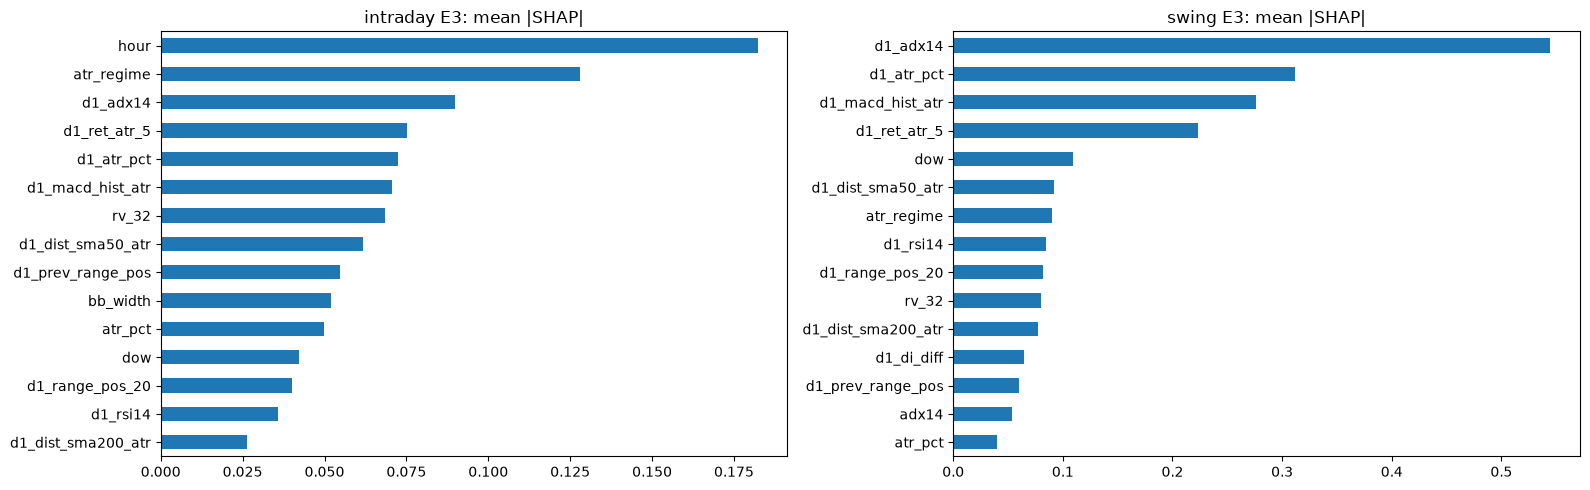

,intraday,swing
0,hour,d1_adx14
1,atr_regime,d1_atr_pct
2,d1_adx14,d1_macd_hist_atr
3,d1_ret_atr_5,d1_ret_atr_5
4,d1_atr_pct,dow
5,d1_macd_hist_atr,d1_dist_sma50_atr
6,rv_32,atr_regime
7,d1_dist_sma50_atr,d1_rsi14
8,d1_prev_range_pos,d1_range_pos_20
9,bb_width,rv_32


In [12]:
# What drives the final models (mean |SHAP| on the last 3 months; |coef| for a logistic model)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
TOP = {}
for ax, (hzn, exp) in zip(axes, CHOSEN.items()):
    model, predict, cols, cals, rule = FINAL2[hzn]
    fr = FR[hzn]
    recent = fr[(fr["date"] >= "2025-11-01") & CV.usable(fr)][cols]
    X = recent.sample(min(2000, len(recent)), random_state=SEED)
    if exp.model == "logit":
        imp = pd.Series(np.abs(model.sides["bull"]["coef"]) + np.abs(model.sides["bear"]["coef"]), index=cols)
        label = "|coef| bull + bear (standardized)"
    else:
        boosters = model.values() if exp.model == "lgbm" else [model]
        imp = pd.Series(0.0, index=cols)
        for b in boosters:
            sv = shap.TreeExplainer(b).shap_values(X)
            sv = np.abs(np.asarray(sv))
            imp += sv.mean(axis=tuple(i for i in range(sv.ndim) if sv.shape[i] != len(cols)))
        label = "mean |SHAP|"
    imp = imp.sort_values(ascending=False)
    TOP[hzn] = imp
    imp.head(15)[::-1].plot.barh(ax=ax)
    ax.set_title(f"{hzn} {exp.id}: {label}")
plt.tight_layout()
plt.show()
display(pd.DataFrame({h: v.head(10).index for h, v in TOP.items()}))

## Results (รายงาน v0.2)

> **ผู้อ่าน:** ทีม harness · **วันที่:** 2026-10-04 · **version:** `xau-bullbear-0.2.0` · **สถานะ:** research — ยังไม่ต่อ backend

### บทสรุป
- **เกณฑ์ที่ตั้งไว้ก่อนรัน "ชนะ always-long แบบมีนัยสำคัญ" — ไม่ผ่าน** ทั้งสอง horizon และทั้ง 6 การทดลอง
- ด้าน ML ดีขึ้นเล็กน้อยและโมเดลง่ายลง: กฎที่ประกาศไว้เลือก **E3 (LightGBM + uniqueness weights + feature 20 ตัว)** ทั้ง intraday และ swing — AUC เฉลี่ยข้าม 10 เดือน intraday 0.587 → **0.595**, swing 0.565 → **0.585**
- สัญญาณที่ **เสถียรที่สุดคือ P_bear** (intraday AUC 0.62, ต่ำสุดรายเดือน 0.58) = โมเดลบอกได้ค่อนข้างสม่ำเสมอว่า "ตอนไหน short มีโอกาสชนะ/ไม่ชนะ" — ตรงกับปัญหาของระบบ LLM ที่ short เกือบตลอด

### ผลเทรด out-of-sample แบบ nested (มิ.ย. 2025 → ม.ค. 2026, กติการะบบ, หักต้นทุน)

| | trades | win rate | PF | expectancy (CI 90%) | vs always-long (CI 90%) | long |
|---|---|---|---|---|---|---|
| **intraday E3** | 79 | 48.1% | 1.08 | +0.04R (−0.16 … +0.25) | −0.15 … +0.26 | 85% |
| intraday always-long | 1,608 | 43.4% | 0.98 | −0.01R | – | 100% |
| intraday always-short | 1,374 | 36.0% | 0.85 | **−0.09R** (−0.15 … −0.03) | | 0% |
| intraday SMA20/50 | 262 | 43.5% | 1.15 | +0.08R | | 49% |
| **swing E3** | 134 | 49.3% | **1.47** | **+0.23R (+0.06 … +0.40)** | −0.19 … +0.27 | 100% |
| swing always-long | 158 | 48.1% | 1.38 | +0.19R (+0.03 … +0.35) | – | 100% |
| swing always-short | 124 | 25.8% | 0.73 | **−0.19R** | | 0% |

- **swing E3** มี expectancy เป็นบวกอย่างมีนัยสำคัญ (CI ไม่คร่อม 0) แต่ **เกือบเท่ากับการ long ทุกแท่ง** — 7 ใน 8 เดือนสัญญาณเป็น long ทุกแท่ง; ช่วงเดือนที่ไม่เคยเห็น (มิ.ย.–ก.ย.) ดีกว่า always-long เล็กน้อย (+0.18R vs +0.12R) แต่อยู่ในช่วง noise
- **intraday E3 ไม่น่าเชื่อถือ:** กำไรทั้งหมดมาจากช่วงที่เคยเห็นใน v0.1 (ต.ค.–ม.ค. +0.33R) ส่วนเดือนที่ไม่เคยเห็น **ขาดทุน −0.39R** (32 เทรด, PF 0.38)
- **always-short แพ้ทุก horizon ทุกช่วง** — ยืนยันข้อค้นพบของ v0.1 อีกครั้งบนข้อมูลที่กว้างกว่า (8 เดือน)
- pybroker กับ replica ให้ผลของโมเดลตรงกัน (intraday 79 เทรด PF 1.08 ทั้งคู่, swing PF 1.50 vs 1.47) — baseline always-long ต่างกันมากกว่า เพราะ pybroker ไม่เช็ค stop ในแท่งที่เข้า และเทรดนั้นเกิดทุกแท่ง
- buy & hold ช่วงเดียวกัน: +47% (intraday window) / +33% (swing window)

### อะไรช่วย อะไรไม่ช่วย (AUC เฉลี่ยข้าม fold)

| การทดลอง | intraday | swing | สรุป |
|---|---|---|---|
| E0 v0.1 setup | 0.587 | 0.565 | จุดอ้างอิง |
| E1 + uniqueness weights | 0.580 | 0.542 | ไม่ช่วยเมื่อใช้ feature ครบ |
| E2 logistic regression | 0.546 | 0.524 | แย่กว่า — ความสัมพันธ์ไม่เป็นเส้นตรง |
| **E3 + weights, feature 20 ตัว** | **0.595** | **0.585** | **ดีที่สุด** — ตัด feature จังหวะเข้าที่เป็น noise ออก |
| E4 3-class | 0.586 | 0.556 | ไม่ต่าง |
| E5 + level/session | 0.577 | 0.564 | ไม่ช่วย — high/low วัน/สัปดาห์ก่อนไม่ได้เพิ่มข้อมูล |

feature สำคัญของโมเดลสุดท้าย: `hour`, `atr_regime`, `d1_adx14`, `d1_ret_atr_5`, `d1_atr_pct` — **บริบทรายวัน + ระดับความผันผวน + ชั่วโมง** เหมือน v0.1

### ข้อจำกัด
1. **ไม่มี holdout สะอาด:** ม.ค. 2026 คือข้อมูลล่าสุดที่มี และ ต.ค.–ม.ค. เคยเปิดดูใน v0.1 → nested walk-forward ป้องกันการจูนตามผลได้ แต่การออกแบบ v0.2 อาจได้อิทธิพลทางอ้อม จึงแยกรายงานเดือนที่ไม่เคยเห็น
2. ข้อมูล Aug–Sep 2026 หาไม่ได้จากเครื่องนี้ (Dukascopy เชื่อมต่อไม่ได้, Yahoo มีแค่ futures + 15m ย้อนหลัง 60 วัน)
3. regime เดียว (ทองขาขึ้น, เหนือ SMA50 & SMA200 รายวัน 91% ของเวลา) — ทุกอย่างที่ "long" ดูดี
4. swing มีเทรดแค่ ~130 ไม้ใน 8 เดือน — CI กว้าง

### ข้อเสนอ (เหมือนเดิมแต่หนักแน่นขึ้น)
- ❌ **ไม่ใช้เป็น policy gate และไม่ใช้สร้างสัญญาณเข้าเอง** — ยังไม่ชนะ always-long
- ✅ **ใช้ P_bear ของ intraday เป็นหลักฐานให้ analyst/risk:** "ถ้า LLM จะ short แต่ P_bear ต่ำกว่า break-even ของ R:R ที่เสนอ → เตือน" — นี่คือส่วนที่เสถียรที่สุดของโมเดล (AUC ≥ 0.58 ทุกเดือน) และตรงกับจุดที่ระบบขาดทุน (always-short −0.09 ถึง −0.19R)
- โมเดลที่บันทึก: `models/v2/xau_{intraday,swing}_ct25.{bull,bear}.txt` + `.json` (E3, τ = 0.375 / 0.40, m = 0) — โหลดผ่าน `xau_ml/predictor.py` แล้วได้ค่าตรงกับใน notebook

## Next steps

1. **ตัดสินด้วย Aug–Sep 2026 ผ่าน backtest API ของ harness** เมื่อหาข้อมูลได้ — ทดสอบ "LLM เดิม" vs "LLM + คำเตือน P_bear" บนช่วงเดียวกัน
2. หาแหล่งข้อมูล spot ที่เชื่อมต่อได้ (เช่น export จาก MT5 ของ broker เดิม) สำหรับ Feb–Sep 2026 และอุดช่องที่หาย — ไฟล์เดียวกับ broker จะดีที่สุด
3. **meta-labeling:** เก็บข้อเสนอจริงของ LLM จาก backtest แล้วเทรนโมเดลกรอง "ข้อเสนอนี้จะชนะไหม" (ต้องอนุมัติค่า LLM)
4. ถ้าจะทำต่อด้าน feature: E3 บอกว่า **น้อยกว่าดีกว่า** — ลองบริบทจากตลาดอื่น (DXY, US 10Y yield, real rates) แทน indicator ของแท่งราคาเอง